# Face Liveness Detection: người thật (REAL) hay giả (FAKE)

| Nhận diện | Công cụ | Ngưỡng |
|---|---|---|
| Khuôn mặt | MediaPipe Face Landmarker | có / không thấy mặt |
| Mở / nhắm mắt | MediaPipe (blendshape `eyeBlink`, 0 = mở … 1 = nhắm) | `blink ≥ 0.5` → **CLOSED**, còn lại **OPEN** |
| Quay đầu trái / phải | MediaPipe (góc `yaw`) | `yaw > 12°` → **RIGHT**, `< −12°` → **LEFT** (theo ảnh hiển thị) |
| Ngẩng / cúi đầu | MediaPipe (góc `pitch`) | `pitch < −10°` → **UP**, `> 10°` → **DOWN** |
| **REAL / FAKE** | **MiniVision** MiniFASNet (điểm `p_real`) | `p_real ≥ ngưỡng` → **REAL**; ngưỡng **tự tìm** bằng ROC (Youden) trên tập train |

* **ML Kit** không có SDK Python, nên dùng MediaPipe (cũng của Google) để lấy các thông tin tương đương.
* Mắt và góc đầu **chỉ để hiển thị**: video phát lại cũng chớp mắt, quay đầu được. Quyết định REAL/FAKE dựa vào MiniVision.
* Dataset: **NUAA Photograph Imposter Database** (`data/dataset.zip`), REAL = người thật, FAKE = ảnh in.

In [1]:
# ===== Import, thư mục =====
import os, sys, json, math, time, zipfile, platform
from pathlib import Path
from collections import deque
import numpy as np, pandas as pd, cv2, torch, requests, mediapipe as mp
import torch.nn.functional as F, matplotlib.pyplot as plt
from mediapipe.tasks.python import vision as V, BaseOptions
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display
from tqdm.auto import tqdm

ROOT = Path.cwd(); MODELS, DATA, RESULTS = ROOT / "models", ROOT / "data", ROOT / "results"
for d in (MODELS, DATA, RESULTS): d.mkdir(exist_ok=True)
RUN_CAMERA = os.environ.get("LIVENESS_NO_CAMERA") != "1"     # đặt LIVENESS_NO_CAMERA=1 để bỏ qua camera

# ===== NGƯỠNG (sửa ở đây) =====
EYE_CLOSED = 0.5    # blink >= 0.5 -> NHẮM mắt (CLOSED); < 0.5 -> MỞ (OPEN)
YAW_TH     = 12     # yaw > 12° -> quay PHẢI (RIGHT); yaw < -12° -> quay TRÁI (LEFT)
PITCH_TH   = 10     # pitch < -10° -> NGẨNG (UP); pitch > 10° -> CÚI (DOWN)
REAL_TH    = None   # p_real >= REAL_TH -> REAL. None = tự tìm ở mục 5 (Youden trên tập train)

## 1. Tải model
MiniVision (code `MiniFASNet.py` + 2 file trọng số, cố định theo commit) và MediaPipe `face_landmarker.task`. File đã có thì bỏ qua.

In [2]:
def download(url, dest):
    if not dest.exists():
        r = requests.get(url, timeout=60); r.raise_for_status(); dest.write_bytes(r.content)

MV = "https://raw.githubusercontent.com/minivision-ai/Silent-Face-Anti-Spoofing/b6d5f04ad78778917853b25c778acef6d5626d15"
for f in ["src/model_lib/MiniFASNet.py", "resources/anti_spoof_models/2.7_80x80_MiniFASNetV2.pth",
          "resources/anti_spoof_models/4_0_0_80x80_MiniFASNetV1SE.pth"]:
    download(f"{MV}/{f}", MODELS / Path(f).name)
download("https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task",
         MODELS / "face_landmarker.task")
print(sorted(p.name for p in MODELS.glob("*.*")))

['2.7_80x80_MiniFASNetV2.pth', '4_0_0_80x80_MiniFASNetV1SE.pth', 'MiniFASNet.py', 'face_landmarker.task']


## 2. Các hàm nhận diện
* `p_real(ảnh, hộp_mặt)`: **MiniVision**. Cắt vùng mặt ×2.7 và ×4.0, resize 80×80, đưa vào 2 mạng, trung bình `softmax`, lấy lớp 1 (người thật).
* `analyze(ảnh)`: **MediaPipe** tìm mặt, trả về hộp mặt, `blink`, `yaw`, `pitch` và `p_real`.
* `state(blink, yaw, pitch)`: đổi số đo thành chữ theo **NGƯỠNG** ở trên.

In [3]:
# ===== MiniVision =====
sys.path.insert(0, str(MODELS))
from MiniFASNet import MiniFASNetV2, MiniFASNetV1SE

def load_net(fname, ctor):
    net = ctor(conv6_kernel=(5, 5), num_classes=3)                          # ảnh vào 80x80
    sd = {k.replace("module.", ""): v for k, v in torch.load(MODELS / fname, map_location="cpu").items()}
    sd = {k.replace("se_fc", "se_module.fc").replace("se_bn", "se_module.bn"): v for k, v in sd.items()}  # tên khối SE
    net.load_state_dict(sd); return net.eval()

NETS = [(2.7, load_net("2.7_80x80_MiniFASNetV2.pth", MiniFASNetV2)),       # (tỉ lệ cắt, mạng)
        (4.0, load_net("4_0_0_80x80_MiniFASNetV1SE.pth", MiniFASNetV1SE))]

@torch.no_grad()
def p_real(img, box):
    """Xác suất là người thật (0..1)."""
    x, y, w, h = box; H, W = img.shape[:2]; ps = []
    for scale, net in NETS:
        k, cx, cy = min((H - 1) / h, (W - 1) / w, scale), x + w / 2, y + h / 2              # mở rộng vùng mặt k lần
        x1, y1, x2, y2 = int(max(0, cx - k * w / 2)), int(max(0, cy - k * h / 2)), int(min(W - 1, cx + k * w / 2)), int(min(H - 1, cy + k * h / 2))
        crop = cv2.resize(img[y1:y2 + 1, x1:x2 + 1], (80, 80))
        ps.append(F.softmax(net(torch.from_numpy(crop.transpose(2, 0, 1).astype(np.float32))[None]), 1)[0, 1].item())
    return float(np.mean(ps))                                              # trung bình 2 mạng

# ===== MediaPipe: mặt, mắt, góc đầu =====
def make_landmarker(video=False):
    return V.FaceLandmarker.create_from_options(V.FaceLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=str(MODELS / "face_landmarker.task")), num_faces=1,
        running_mode=V.RunningMode.VIDEO if video else V.RunningMode.IMAGE,
        output_face_blendshapes=True, output_facial_transformation_matrixes=True))

def analyze(img, lmk, ts=None):
    """Trả về dict(box, blink, yaw, pitch, p_real), hoặc None nếu không thấy mặt. ts (ms) dùng cho chế độ video."""
    mimg = mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    res = lmk.detect(mimg) if ts is None else lmk.detect_for_video(mimg, ts)
    if not res.face_landmarks: return None
    H, W = img.shape[:2]
    pts = np.array([[p.x * W, p.y * H] for p in res.face_landmarks[0]])   # 478 điểm mốc trên mặt
    (x0, y0), (x1, y1) = pts.min(0), pts.max(0); box = (x0, y0, x1 - x0, y1 - y0)
    bs = {c.category_name: c.score for c in res.face_blendshapes[0]}
    R = np.array(res.facial_transformation_matrixes[0])[:3, :3]; R = R / np.linalg.norm(R, axis=0)   # ma trận xoay đầu
    return dict(box=box, blink=(bs["eyeBlinkLeft"] + bs["eyeBlinkRight"]) / 2,          # 0 = mở ... 1 = nhắm
                yaw=math.degrees(math.atan2(R[0, 2], R[2, 2])),                         # > 0: quay sang phải ảnh
                pitch=math.degrees(math.asin(np.clip(-R[1, 2], -1, 1))),                # > 0: cúi xuống
                p_real=p_real(img, box))

def state(blink, yaw, pitch):
    """Áp NGƯỠNG: mắt, quay trái/phải, ngẩng/cúi."""
    return dict(eye="CLOSED" if blink >= EYE_CLOSED else "OPEN",
                turn="RIGHT" if yaw > YAW_TH else "LEFT" if yaw < -YAW_TH else "CENTER",
                tilt="DOWN" if pitch > PITCH_TH else "UP" if pitch < -PITCH_TH else "CENTER")

print(state(blink=0.7, yaw=-20, pitch=-15))   # ví dụ: nhắm mắt, quay trái, ngẩng đầu

{'eye': 'CLOSED', 'turn': 'LEFT', 'tilt': 'UP'}

## 3. Dataset NUAA và chấm điểm
* Tự giải nén `data/dataset.zip` nếu chưa có `data/raw/`. Train/test lấy theo 4 file `.txt` của dataset. `ClientRaw` = REAL, `ImposterRaw` = FAKE.
* Mỗi ảnh được chạy `analyze`. Kết quả lưu `results/frame_scores.csv`; lần sau đọc lại cache (chạy hết khoảng 15 phút trên CPU).

In [4]:
if not (DATA / "raw").exists(): zipfile.ZipFile(DATA / "dataset.zip").extractall(DATA)
rows = []
for txt in (DATA / "raw").glob("*_raw.txt"):                 # client/imposter _ train/test _raw.txt
    for line in txt.read_text().split():
        p = DATA / "raw" / line.split("/raw/", 1)[1]           # bỏ tiền tố đường dẫn Kaggle
        rows.append(dict(path=str(p), group=f"{p.parts[-3]}/{p.stem}", seq=f"{p.parts[-3]}/{p.stem.rsplit('_', 1)[0]}",
                         frame_no=int(p.stem.rsplit("_", 1)[1]), split="train" if "_train_" in txt.name else "test",
                         label=int(p.parts[-3] == "ClientRaw")))           # 1 = REAL, 0 = FAKE
meta = pd.DataFrame(rows).sort_values(["seq", "frame_no"], ignore_index=True)
display(pd.crosstab(meta.split, meta.label.map({1: "REAL", 0: "FAKE"})))

CACHE = RESULTS / "frame_scores.csv"
if CACHE.exists() and set(pd.read_csv(CACHE).group) == set(meta.group):
    df = pd.read_csv(CACHE)
else:
    lmk, out = make_landmarker(), []
    for r in tqdm(meta.itertuples(), total=len(meta)):
        f = analyze(cv2.imread(r.path), lmk)
        out.append(dict(group=r.group, split=r.split, label=r.label, found=f is not None,
                        **({k: f[k] for k in ("p_real", "blink", "yaw", "pitch")} if f else {})))
    df = pd.DataFrame(out); df.to_csv(CACHE, index=False)
df = df[df.found]
print(f"{len(df)}/{len(meta)} ảnh thấy mặt")

label,FAKE,REAL
split,,
test,5761,3362
train,1748,1743


12606/12614 ảnh thấy mặt


## 4. Ngưỡng mắt và góc đầu
Biểu đồ phân bố `blink`, `yaw`, `pitch` trên dataset, vạch đứt là ngưỡng. Bảng dưới đếm số ảnh rơi vào từng trạng thái.

Dataset **không có nhãn** "mắt nhắm" hay "quay đầu", nên các ngưỡng này là **lựa chọn thiết kế** (không học từ dữ liệu). Biểu đồ cho thấy chúng nằm ở đâu so với dữ liệu thật: phần lớn người trong NUAA mở mắt và nhìn thẳng.

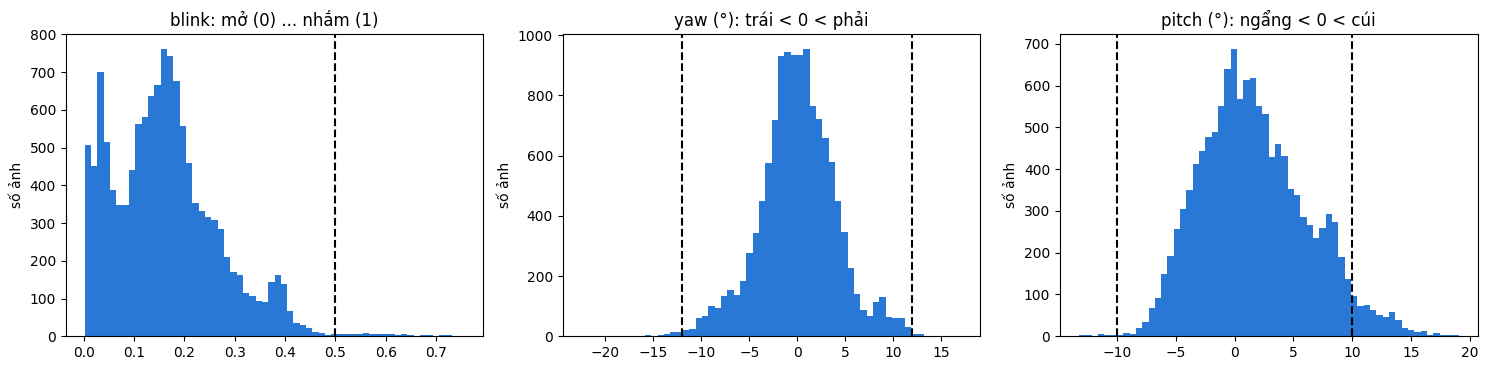

,eye,turn,tilt
OPEN,12518,0,0
CLOSED,88,0,0
CENTER,0,12534,12033
LEFT,0,50,0
RIGHT,0,22,0
DOWN,0,0,557
UP,0,0,16


In [5]:
st = pd.DataFrame([state(b, y, p) for b, y, p in zip(df.blink, df.yaw, df.pitch)], index=df.index)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, col, ths, name in [(ax[0], "blink", [EYE_CLOSED], "blink: mở (0) ... nhắm (1)"),
                          (ax[1], "yaw", [-YAW_TH, YAW_TH], "yaw (°): trái < 0 < phải"),
                          (ax[2], "pitch", [-PITCH_TH, PITCH_TH], "pitch (°): ngẩng < 0 < cúi")]:
    a.hist(df[col], 60, color="#2a78d6")
    for t in ths: a.axvline(t, color="k", ls="--")
    a.set(title=name, ylabel="số ảnh")
plt.tight_layout(); plt.show()

display(pd.concat({c: st[c].value_counts() for c in st}, axis=1).fillna(0).astype(int))

## 5. REAL / FAKE: tìm ngưỡng và đánh giá
1. **Tìm ngưỡng trên TRAIN** bằng ROC: chọn ngưỡng làm `TPR − FPR` lớn nhất (Youden).
2. **Đánh giá trên TEST** với ngưỡng đó: Accuracy, Confusion Matrix, ROC, AUC.

* **FAR** = tỉ lệ FAKE bị nhận nhầm là REAL. **FRR** = tỉ lệ REAL bị từ chối nhầm.

Ngưỡng REAL/FAKE (Youden trên train) = 0.108
TEST (9122 ảnh): Accuracy = 0.9993 | AUC = 1.0000 | FAR = 0.0010 | FRR = 0.0000


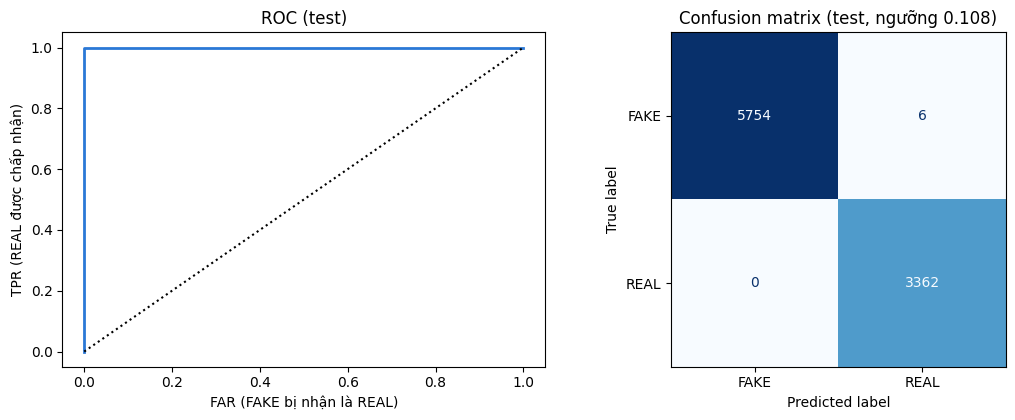

In [6]:
tr, te = df[df.split == "train"], df[df.split == "test"]

fpr, tpr, thr = roc_curve(tr.label, tr.p_real)                                   # TRAIN -> tìm ngưỡng
THRESHOLD = float(thr[np.argmax(tpr - fpr)]) if REAL_TH is None else REAL_TH
json.dump({"threshold": THRESHOLD}, open(RESULTS / "threshold.json", "w"))

cm = confusion_matrix(te.label, (te.p_real >= THRESHOLD).astype(int))             # TEST -> đánh giá
(TN, FP), (FN, TP) = cm
print(f"Ngưỡng REAL/FAKE (Youden trên train) = {THRESHOLD:.3f}")
print(f"TEST ({len(te)} ảnh): Accuracy = {(TP + TN) / cm.sum():.4f} | AUC = {roc_auc_score(te.label, te.p_real):.4f}"
      f" | FAR = {FP / (FP + TN):.4f} | FRR = {FN / (FN + TP):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
f2, t2, _ = roc_curve(te.label, te.p_real)
ax[0].plot(f2, t2, lw=2, color="#2a78d6"); ax[0].plot([0, 1], [0, 1], "k:")
ax[0].set(title="ROC (test)", xlabel="FAR (FAKE bị nhận là REAL)", ylabel="TPR (REAL được chấp nhận)")
ConfusionMatrixDisplay(cm, display_labels=["FAKE", "REAL"]).plot(ax=ax[1], colorbar=False, cmap="Blues")
ax[1].set_title(f"Confusion matrix (test, ngưỡng {THRESHOLD:.3f})")
plt.tight_layout(); plt.show()

## 6. Realtime
Mỗi khung hình: `analyze` → lấy **median `p_real` của 15 khung gần nhất** (chống nhiễu) → so với ngưỡng → vẽ **REAL/FAKE**, trạng thái mắt, quay đầu, ngẩng/cúi lên ảnh. Cần ít nhất 8 khung mới kết luận (hiện `...`).

Cell dưới thử trên 2 chuỗi REAL và 2 chuỗi FAKE của tập test (giả lập camera, không cần webcam). Cell cuối mở camera: nhấn **q** hoặc **ESC** để thoát.

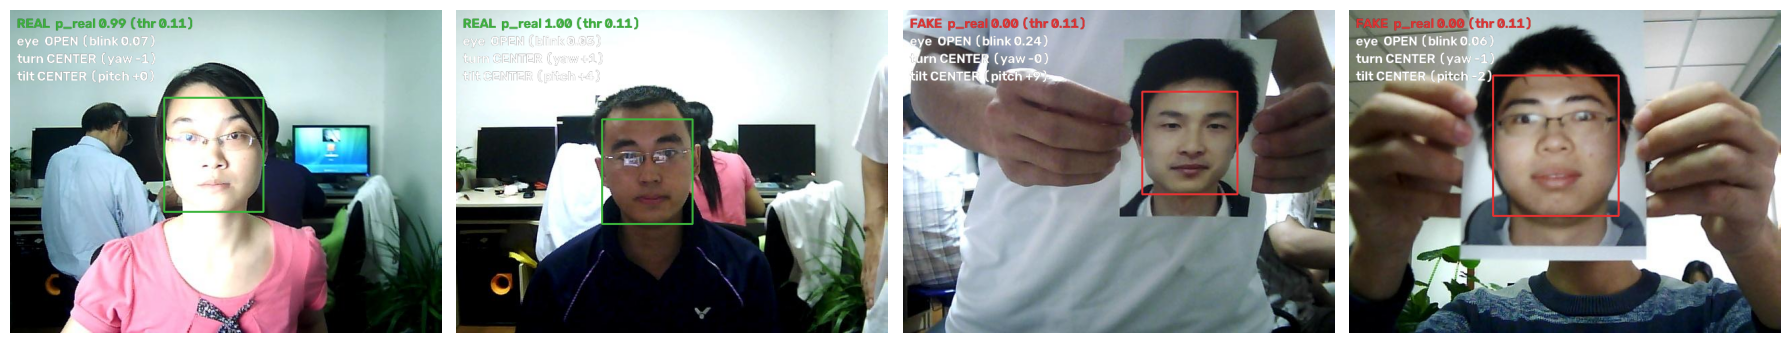

In [7]:
FONT = cv2.FONT_HERSHEY_SIMPLEX

def step(frame, lmk, ts, hist, thr):
    """Xử lý 1 khung hình, vẽ kết quả lên ảnh. hist = p_real các khung gần nhất. Trả về (ảnh, nhãn)."""
    f = analyze(frame, lmk, ts)
    if f is None:
        cv2.putText(frame, "NO FACE", (20, 40), FONT, 1, (150, 150, 150), 2); return frame, "NO FACE"
    hist.append(f["p_real"]); score = float(np.median(hist))
    label = "..." if len(hist) < 8 else "REAL" if score >= thr else "FAKE"
    color = {"REAL": (60, 180, 60), "FAKE": (50, 50, 230)}.get(label, (200, 200, 200))   # màu BGR
    s = state(f["blink"], f["yaw"], f["pitch"])
    x, y, w, h = map(int, f["box"]); cv2.rectangle(frame, (x, y), (x + w, y + h), color, 2)
    for i, t in enumerate([f"{label}  p_real {score:.2f} (thr {thr:.2f})", f"eye  {s['eye']} (blink {f['blink']:.2f})",
                           f"turn {s['turn']} (yaw {f['yaw']:+.0f})", f"tilt {s['tilt']} (pitch {f['pitch']:+.0f})"]):
        cv2.putText(frame, t, (10, 28 + 26 * i), FONT, 0.65, (0, 0, 0), 4)                 # viền đen
        cv2.putText(frame, t, (10, 28 + 26 * i), FONT, 0.65, color if i == 0 else (255, 255, 255), 2)
    return frame, label

# ===== Thử trên chuỗi test (mỗi chuỗi là các khung liên tiếp, ~20 khung/giây) =====
shots = []
for lab in (1, 0):
    for seq in meta[(meta.split == "test") & (meta.label == lab)].seq.unique()[[0, -1]]:   # 2 chuỗi mỗi loại
        lmk, hist = make_landmarker(video=True), deque(maxlen=15)
        for r in meta[meta.seq == seq].head(30).itertuples():
            img, res = step(cv2.imread(r.path), lmk, r.frame_no * 50, hist, THRESHOLD)     # 50 ms/khung
            if res != "NO FACE": shot = img                                                # giữ khung cuối có mặt
        shots.append(shot)
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for a, im in zip(ax, shots): a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); a.axis("off")
plt.tight_layout(); plt.show()

In [8]:
# ===== Camera realtime: q / ESC để thoát =====
def run_camera(src=0, thr=None):
    thr = THRESHOLD if thr is None else thr
    cap = cv2.VideoCapture(src, cv2.CAP_DSHOW) if platform.system() == "Windows" else cv2.VideoCapture(src)
    lmk, hist, t0, ts = make_landmarker(video=True), deque(maxlen=15), time.time(), 0
    try:
        while True:
            ok, frame = cap.read()
            if not ok: break
            ts = max(ts + 1, int((time.time() - t0) * 1000))                  # mốc thời gian tăng dần (ms)
            cv2.imshow("Liveness", step(cv2.flip(frame, 1), lmk, ts, hist, thr)[0])
            if cv2.waitKey(1) & 0xFF in (ord("q"), 27) or cv2.getWindowProperty("Liveness", cv2.WND_PROP_VISIBLE) < 1:
                break
    finally:
        cap.release(); cv2.destroyAllWindows()

if RUN_CAMERA: run_camera()          # muốn khắt khe hơn với ảnh/video giả: run_camera(thr=0.9)

## 7. Kết luận
* **REAL/FAKE:** ngưỡng tìm bằng ROC (Youden) trên train, đánh giá trên test (mục 5). Trên NUAA, MiniVision tách REAL/FAKE gần như hoàn hảo, nên nhiều ngưỡng đều cho kết quả tốt. Ngưỡng tìm được khá thấp; với camera và điện thoại/màn hình thật nên thử ngưỡng cao hơn (`run_camera(thr=0.9)`).
* **Mắt / góc đầu:** ngưỡng `blink 0.5`, `yaw ±12°`, `pitch ±10°` là lựa chọn thiết kế (dataset không có nhãn cho các trạng thái này). Chúng chỉ để hiển thị và **không chứng minh người thật**, vì video phát lại vẫn chớp mắt, quay đầu được.
* **Giới hạn:** NUAA chỉ có tấn công bằng ảnh in (không có video/màn hình), webcam cũ, 15 người. Chưa thử realtime với người thật trước webcam trong lần chạy tự động.